# Early Academic Risk Prediction and Student Support System
## Notebook 07: Feature Comparison Experiment (18 vs. 12 Features)

---

### 1. Introduction and Experiment Objective
In our completed project, we developed an early warning system using **18 features** to predict student academic risk at the **Day 30** mark. Our primary model, **Logistic Regression** tuned to a decision threshold of **0.40**, achieved a test set recall of **73.41%** and precision of **63.14%**.

However, the 18-feature model relies on **6 student background and demographic features**:
* `gender`
* `region`
* `highest_education`
* `imd_band` (Index of Multiple Deprivation decile)
* `age_band`
* `disability`

#### Key Questions Investigated in this Experiment:
1. **Predictive Performance:** Are student background attributes strictly necessary to achieve high risk detection accuracy, or do early virtual learning engagement and early academic performance features capture the vast majority of predictive signal?
2. **Subgroup Disparities:** In Notebook 06, we observed that students entering with lower qualifications or declared disabilities experienced elevated false alarm rates (approaching 49%). Does removing background features reduce demographic differences in false positive rates?
3. **Data Collection Burden:** An engagement-focused model eliminates the need for institutions or teachers to collect, store, and process sensitive student demographic and socioeconomic characteristics.

#### Experimental Setup & Strict Integrity Rules:
* **Model A (18 features):** The existing production model configuration.
* **Model B (12 features):** Keeps course presentation (`code_module`, `code_presentation`) and all 10 academic and VLE engagement features, excluding only the 6 demographic attributes.
* **Identical Methodology:** Both models are evaluated on the exact same dataset, the exact same eligible cohort, the exact same `GroupShuffleSplit` (80/20 grouped on `id_student`), the exact same algorithm (`LogisticRegression`), and the existing operational threshold (`0.40`).

In [1]:
# Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    recall_score, precision_score, f1_score, accuracy_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("All required libraries imported successfully!")

All required libraries imported successfully!

---
### 2. Load the Processed Dataset
We load the clean, leakage-free modeling dataset prepared in Notebook 03: `data/processed/student_model_data.csv`.

Every row represents one student course enrollment with early indicators calculated strictly on or before **Day 30**. The target variable is `target` (1 = At Risk [Fail/Withdrawn after Day 30], 0 = Not At Risk [Pass/Distinction]).

In [2]:
# Load processed modeling dataset
data_path = 'data/processed/student_model_data.csv'
df = pd.read_csv(data_path)

print("Dataset successfully loaded!")
print(f"Total Rows:    {len(df):,}")
print(f"Total Columns: {len(df.columns)}")
df.head()

Dataset successfully loaded!
Total Rows:    27,373
Total Columns: 20

In [3]:
# Check the target class balance
target_counts = df['target'].value_counts()
target_pcts = df['target'].value_counts(normalize=True) * 100

print("=== Target Class Distribution ===")
for cls, lbl in [(0, "Not At Risk (0)"), (1, "At Risk (1)")]:
    print(f"- {lbl}: {target_counts[cls]:,} enrollments ({target_pcts[cls]:.2f}%)")

=== Target Class Distribution ===
- Not At Risk (0): 15,385 enrollments (56.21%)
- At Risk (1): 11,988 enrollments (43.79%)

---
### 3. Define Model A Features (Existing 18 Features)
Model A uses all 18 input features from our production model:
* **8 Categorical Features:** `code_module`, `code_presentation`, `gender`, `region`, `highest_education`, `imd_band`, `age_band`, `disability`
* **10 Numerical Features:** `num_of_prev_attempts`, `studied_credits`, `date_registration`, `total_clicks`, `active_days`, `unique_sites`, `pre_course_clicks`, `early_assessments_submitted`, `early_avg_score`, `has_early_submission`

In [4]:
# Define full feature set for Model A
cat_features_a = [
    'code_module', 'code_presentation', 'gender', 'region',
    'highest_education', 'imd_band', 'age_band', 'disability'
]

num_features_a = [
    'num_of_prev_attempts', 'studied_credits', 'date_registration',
    'total_clicks', 'active_days', 'unique_sites', 'pre_course_clicks',
    'early_assessments_submitted', 'early_avg_score', 'has_early_submission'
]

features_a = cat_features_a + num_features_a

print(f"Model A Feature Count: {len(features_a)}")
print(f"- Categorical ({len(cat_features_a)}): {cat_features_a}")
print(f"- Numerical   ({len(num_features_a)}): {num_features_a}")

Model A Feature Count: 18
- Categorical (8): ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']
- Numerical   (10): ['num_of_prev_attempts', 'studied_credits', 'date_registration', 'total_clicks', 'active_days', 'unique_sites', 'pre_course_clicks', 'early_assessments_submitted', 'early_avg_score', 'has_early_submission']

---
### 4. Define Model B Features (Reduced 12 Features)
Model B excludes all 6 student background and demographic features:
* Excluded: `gender`, `region`, `highest_education`, `imd_band`, `age_band`, `disability`

It retains:
* **2 Categorical Features:** `code_module`, `code_presentation` (course structure context)
* **10 Numerical Features:** All 10 academic history and Day 1–30 engagement features

In [5]:
# Define reduced feature set for Model B (12 features)
cat_features_b = ['code_module', 'code_presentation']
num_features_b = [
    'num_of_prev_attempts', 'studied_credits', 'date_registration',
    'total_clicks', 'active_days', 'unique_sites', 'pre_course_clicks',
    'early_assessments_submitted', 'early_avg_score', 'has_early_submission'
]

features_b = cat_features_b + num_features_b
excluded_features = list(set(features_a) - set(features_b))

print(f"Model B Feature Count: {len(features_b)}")
print(f"- Categorical ({len(cat_features_b)}): {cat_features_b}")
print(f"- Numerical   ({len(num_features_b)}): {num_features_b}")
print(f"\nExcluded Background Features ({len(excluded_features)}): {sorted(excluded_features)}")

Model B Feature Count: 12
- Categorical (2): ['code_module', 'code_presentation']
- Numerical   (10): ['num_of_prev_attempts', 'studied_credits', 'date_registration', 'total_clicks', 'active_days', 'unique_sites', 'pre_course_clicks', 'early_assessments_submitted', 'early_avg_score', 'has_early_submission']

Excluded Background Features (6): ['age_band', 'disability', 'gender', 'highest_education', 'imd_band', 'region']

---
### 5. Reuse the Existing Train/Test Split
To guarantee a completely fair, unbiased comparison, both models must be trained and evaluated on the **exact same student partitions**.

We recreate the `GroupShuffleSplit` (80% train / 20% test, `random_state=42`) grouped on `id_student` from Notebooks 04, 05, and 06. We verify programmatically that there is **0 student overlap** between training and testing sets.

In [6]:
# Separate features, target, and grouping column
y = df['target'].copy()
groups = df['id_student'].copy()

# Recreate the exact GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, train_size=0.80, random_state=42)
train_idx, test_idx = next(gss.split(df, y, groups=groups))

df_train = df.iloc[train_idx].copy()
df_test = df.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("=== Train / Test Partition Verification ===")
print(f"Training Enrollments: {len(df_train):,} ({len(df_train) / len(df) * 100:.1f}%)")
print(f"Testing Enrollments:  {len(df_test):,} ({len(df_test) / len(df) * 100:.1f}%)")
print(f"Unique Students Train: {groups_train.nunique():,}")
print(f"Unique Students Test:  {groups_test.nunique():,}")

# Confirm zero student leakage
overlap = set(groups_train).intersection(set(groups_test))
print(f"Overlapping Students:  {len(overlap)}")
assert len(overlap) == 0, "Error: Student overlap detected!"
print("Verified: Zero student overlap between training and testing partitions.")

=== Train / Test Partition Verification ===
Training Enrollments: 21,911 (80.0%)
Testing Enrollments:  5,462 (20.0%)
Unique Students Train: 19,768
Unique Students Test:  4,942
Overlapping Students:  0
Verified: Zero student overlap between training and testing partitions.

---
### 6. Build the Two Preprocessing Pipelines
We construct modular Scikit-Learn `ColumnTransformer` preprocessors for both configurations:
* **Numerical Pipeline:** Imputes missing values with the **median**, then standardizes using `StandardScaler`.
* **Categorical Pipeline:** Imputes missing values with `'Missing'`, then applies `OneHotEncoder(handle_unknown='ignore')`.

Each pipeline fits its transformations strictly on the training set, eliminating data leakage.

In [7]:
# 1. Preprocessor for Model A (18 features)
preprocessor_a = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_features_a),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_features_a)
])

# 2. Preprocessor for Model B (12 features)
preprocessor_b = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_features_b),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_features_b)
])

print("Both preprocessing pipelines successfully constructed!")

Both preprocessing pipelines successfully constructed!

---
### 7. Train Both Logistic Regression Models
We construct end-to-end Scikit-Learn pipelines combining the respective preprocessor with `LogisticRegression(max_iter=1000, random_state=42)`. Both models use identical algorithm hyperparameters and are fit on `df_train`.

In [8]:
# Build full model pipelines
pipe_a = Pipeline([
    ('preprocessor', preprocessor_a),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_b = Pipeline([
    ('preprocessor', preprocessor_b),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Fit Model A on 18 features
pipe_a.fit(df_train[features_a], y_train)
print("Model A (18 features) fitted successfully.")

# Fit Model B on 12 features
pipe_b.fit(df_train[features_b], y_train)
print("Model B (12 features) fitted successfully.")

Model A (18 features) fitted successfully.
Model B (12 features) fitted successfully.

---
### 8. Evaluate Both Models
To prevent data leakage, we perform threshold exploration strictly on the **training set** using 5-fold `GroupKFold` cross-validation out-of-fold (OOF) predictions. The held-out test set is never used to select or tune thresholds.

#### Threshold Selection Context:
* **F1 Optimization vs. Operational Capacity:** On training OOF predictions, Model B achieves its numerical peak F1-score of **0.6694** at threshold **0.35** (Recall = 80.48%, Precision = 57.30%).
* **Caseload & Alert Burden:** However, at threshold 0.35, the model flags **61.7%** of all student enrollments (13,509 out of 21,911). In an operational educational setting, alerting on over 60% of students risks alert fatigue and overwhelming advisory capacity.
* **Balanced Operational Choice (0.40):** At threshold **0.40**, the percentage of students flagged decreases by nearly 10 percentage points to **51.8%** (11,341 enrollments; 2,168 fewer student interventions), precision improves to **61.26%**, and recall remains strong at **72.23%**, which comfortably satisfies the project's target design requirement of maintaining $\ge 70\%$ recall for early intervention.
* **Direct Benchmark:** In addition, evaluating both models at **0.40** maintains consistency with the established production threshold from Notebook 05, enabling a direct benchmark between the 18-feature and 12-feature pipelines under identical decision boundaries.

In [9]:
# Generate 5-fold GroupKFold Out-of-Fold (OOF) predicted probabilities for Model B on training data
gkf = GroupKFold(n_splits=5)
oof_probs_b = np.full(len(df_train), np.nan)

for fold, (tr_idx, val_idx) in enumerate(gkf.split(df_train, y_train, groups=groups_train), 1):
    fold_pipe = clone(pipe_b)
    fold_pipe.fit(df_train[features_b].iloc[tr_idx], y_train.iloc[tr_idx])
    oof_probs_b[val_idx] = fold_pipe.predict_proba(df_train[features_b].iloc[val_idx])[:, 1]

assert not np.isnan(oof_probs_b).any(), "Error: Missing OOF predictions in Model B!"
print("5-fold GroupKFold OOF predictions on training set completed for Model B.")

5-fold GroupKFold OOF predictions on training set completed for Model B.

In [10]:
# Evaluate candidate classification thresholds on Model B training OOF predictions
candidate_thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
oof_records = []

for t in candidate_thresholds:
    preds = (oof_probs_b >= t).astype(int)
    cm = confusion_matrix(y_train, preds)
    tn, fp, fn, tp = cm.ravel()
    flagged = tp + fp
    oof_records.append({
        'Threshold': t,
        'Recall': round(recall_score(y_train, preds), 4),
        'Precision': round(precision_score(y_train, preds), 4),
        'F1-Score': round(f1_score(y_train, preds), 4),
        'Flagged N': flagged,
        'Flagged %': round(flagged / len(y_train) * 100, 1),
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn
    })

oof_threshold_df = pd.DataFrame(oof_records)
print("=== Model B Training Out-of-Fold Threshold Performance ===")
print(oof_threshold_df.to_string(index=False))

=== Model B Training Out-of-Fold Threshold Performance ===
 Threshold  Recall  Precision  F1-Score  Flagged N  Flagged %   TP   FP   FN    TN
      0.30  0.8635     0.5386    0.6634      15421       70.4 8306 7115 1313  5177
      0.35  0.8048     0.5730    0.6694      13509       61.7 7741 5768 1878  6524
      0.40  0.7223     0.6126    0.6630      11341       51.8 6948 4393 2671  7899
      0.45  0.6347     0.6576    0.6459       9284       42.4 6105 3179 3514  9113
      0.50  0.5435     0.7021    0.6127       7446       34.0 5228 2218 4391 10074
      0.55  0.4668     0.7420    0.5731       6051       27.6 4490 1561 5129 10731
      0.60  0.3993     0.7793    0.5280       4929       22.5 3841 1088 5778 11204

In [11]:
# Generate test set probabilities and predictions at the project threshold of 0.40
test_prob_a = pipe_a.predict_proba(df_test[features_a])[:, 1]
test_prob_b = pipe_b.predict_proba(df_test[features_b])[:, 1]

# Apply decision threshold of 0.40
test_pred_a = (test_prob_a >= 0.40).astype(int)
test_pred_b = (test_prob_b >= 0.40).astype(int)

# Attach predictions to test DataFrame for subsequent fairness analysis
df_test['pred_a'] = test_pred_a
df_test['prob_a'] = test_prob_a
df_test['pred_b'] = test_pred_b
df_test['prob_b'] = test_prob_b

print("Test set predictions generated at threshold 0.40 for both models.")

Test set predictions generated at threshold 0.40 for both models.

---
### 9. Compare Confusion Matrices and Metrics
We compute standard classification metrics on the held-out test set at the **0.40** threshold:
* **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ (capturing at-risk students)
* **Precision:** $\frac{TP}{TP + FP}$ (alert reliability)
* **F1-Score:** Harmonic mean of Recall and Precision
* **Accuracy:** Overall correct classification rate
* **ROC-AUC:** Area under ROC curve (discrimination capability)
* **PR-AUC:** Area under Precision-Recall curve

In [12]:
# Compute confusion matrices on held-out test data
cm_a = confusion_matrix(y_test, test_pred_a)
tn_a, fp_a, fn_a, tp_a = cm_a.ravel()

cm_b = confusion_matrix(y_test, test_pred_b)
tn_b, fp_b, fn_b, tp_b = cm_b.ravel()

# Assemble side-by-side comparison table
metrics_comparison = pd.DataFrame({
    'Metric': [
        'Recall (Catching At-Risk)',
        'Precision (Alert Reliability)',
        'F1-Score',
        'Overall Accuracy',
        'ROC-AUC Score',
        'PR-AUC Score',
        'True Positives (TP - Caught)',
        'False Positives (FP - False Alarms)',
        'False Negatives (FN - Missed)',
        'True Negatives (TN - Correct Safe)'
    ],
    'Model A (18 Features)': [
        round(recall_score(y_test, test_pred_a), 4),
        round(precision_score(y_test, test_pred_a), 4),
        round(f1_score(y_test, test_pred_a), 4),
        round(accuracy_score(y_test, test_pred_a), 4),
        round(roc_auc_score(y_test, test_prob_a), 4),
        round(average_precision_score(y_test, test_prob_a), 4),
        tp_a,
        fp_a,
        fn_a,
        tn_a
    ],
    'Model B (12 Features)': [
        round(recall_score(y_test, test_pred_b), 4),
        round(precision_score(y_test, test_pred_b), 4),
        round(f1_score(y_test, test_pred_b), 4),
        round(accuracy_score(y_test, test_pred_b), 4),
        round(roc_auc_score(y_test, test_prob_b), 4),
        round(average_precision_score(y_test, test_prob_b), 4),
        tp_b,
        fp_b,
        fn_b,
        tn_b
    ]
})

# Calculate difference (Model B minus Model A)
metrics_comparison['Difference (B - A)'] = [
    round(metrics_comparison.loc[i, 'Model B (12 Features)'] - metrics_comparison.loc[i, 'Model A (18 Features)'], 4)
    for i in range(len(metrics_comparison))
]

print("=== Performance Comparison Summary (Threshold = 0.40) ===")
print(metrics_comparison.to_string(index=False))

=== Performance Comparison Summary (Threshold = 0.40) ===
                             Metric  Model A (18 Features)  Model B (12 Features)  Difference (B - A)
          Recall (Catching At-Risk)                 0.7341                 0.7260             -0.0081
      Precision (Alert Reliability)                 0.6314                 0.6056             -0.0258
                           F1-Score                 0.6789                 0.6604             -0.0185
                   Overall Accuracy                 0.6988                 0.6761             -0.0227
                      ROC-AUC Score                 0.7745                 0.7534             -0.0211
                       PR-AUC Score                 0.7413                 0.7199             -0.0214
       True Positives (TP - Caught)              1739.0000              1720.0000            -19.0000
False Positives (FP - False Alarms)              1015.0000              1120.0000            105.0000
      False Negatives (F

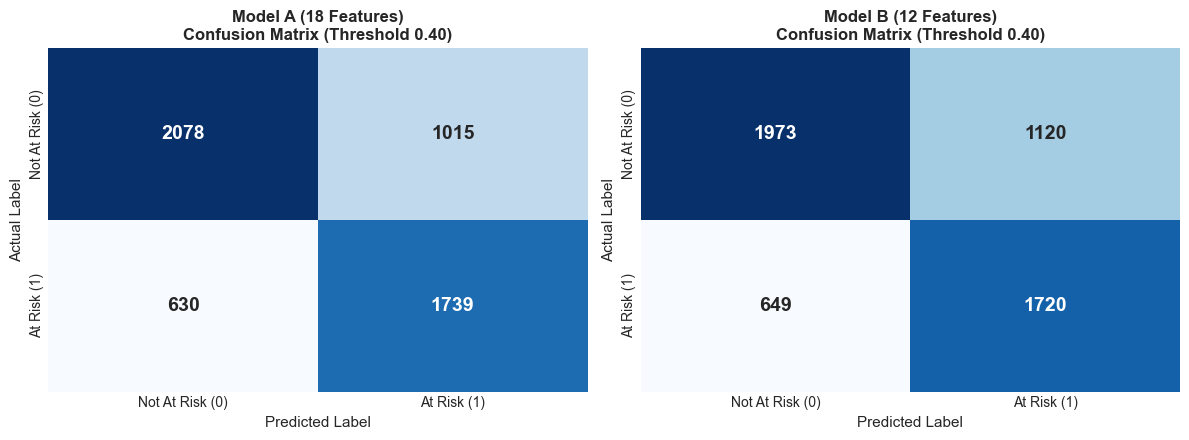

In [13]:
# Visualize confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(cm_a, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Model A (18 Features)\nConfusion Matrix (Threshold 0.40)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('Actual Label', fontsize=11)
axes[0].set_xticklabels(['Not At Risk (0)', 'At Risk (1)'])
axes[0].set_yticklabels(['Not At Risk (0)', 'At Risk (1)'])

sns.heatmap(cm_b, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title('Model B (12 Features)\nConfusion Matrix (Threshold 0.40)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('Actual Label', fontsize=11)
axes[1].set_xticklabels(['Not At Risk (0)', 'At Risk (1)'])
axes[1].set_yticklabels(['Not At Risk (0)', 'At Risk (1)'])

plt.tight_layout()
plt.show()

---
### 10. Compare Group-Wise Performance (Fairness Analysis)
Although the 6 student background features were excluded from training Model B, they remain attached to our test set records. This allows us to directly evaluate whether removing demographic features changes empirical error rates across student groups.

We analyze four demographic dimensions:
1. `gender`
2. `age_band`
3. `highest_education`
4. `disability`

#### Critical Metrics, Denominators, and Sample Size Considerations:
* **Recall (Sensitivity / True Positive Rate):** $\frac{TP}{N_{pos}} = \frac{TP}{TP + FN}$. The denominator is the number of actual at-risk students in that group.
* **False Positive Rate (FPR):** $\frac{FP}{N_{neg}} = \frac{FP}{TN + FP}$. The denominator is the number of actual non-risk students in that group.
* **Sample Size & Variance Warning:**
  * Groups with sufficient test samples: `disability` (4,946 non-disabled, 516 disabled; 2,859 vs 234 non-risk) and `highest_education` major categories (`Lower Than A Level` $N=2,093$, `A Level` $N=2,418$, `HE Qualification` $N=852$). These groups have $N_{neg} > 200$, providing a reasonably stable sample for FPR observations.
  * Very small subgroups: `No Formal quals` ($N=50$, $N_{neg}=20$), `Post Graduate Qualification` ($N=49$, $N_{neg}=34$), and `Age 55<=` ($N=38$, $N_{neg}=27$). Because the denominator is very small, a change of just 1–2 false positives causes large swings in FPR (e.g. 1 student $\approx 3.7\%$ to $5.0\%$). No firm conclusions should be drawn from these small groups.
* **Cautious Interpretation (Non-Causal & Contextual):**
  * Removing demographic features does **not** prove fairness or eliminate discrimination. VLE activity (e.g. login frequency, clicks) may itself correlate with underlying socioeconomic or accessibility barriers.
  * We report observed empirical differences in false positive rates on this test sample, rather than claiming a guarantee of demographic equity.

In [14]:
# Define a helper function to compute subgroup Recall, FPR, and sample sizes for both models
def compute_fairness_comparison(data, group_col):
    rows = []
    for cat, grp in data.groupby(group_col, observed=False):
        n = len(grp)
        n_pos = (grp['target'] == 1).sum()
        n_neg = (grp['target'] == 0).sum()
        
        # Model A metrics
        tp_a = ((grp['target'] == 1) & (grp['pred_a'] == 1)).sum()
        fp_a = ((grp['target'] == 0) & (grp['pred_a'] == 1)).sum()
        rec_a = tp_a / n_pos if n_pos > 0 else np.nan
        fpr_a = fp_a / n_neg if n_neg > 0 else np.nan
        flag_a = tp_a + fp_a
        
        # Model B metrics
        tp_b = ((grp['target'] == 1) & (grp['pred_b'] == 1)).sum()
        fp_b = ((grp['target'] == 0) & (grp['pred_b'] == 1)).sum()
        rec_b = tp_b / n_pos if n_pos > 0 else np.nan
        fpr_b = fp_b / n_neg if n_neg > 0 else np.nan
        flag_b = tp_b + fp_b
        
        rows.append({
            'Subgroup': str(cat),
            'Total N': n,
            'Actual Risk (Pos)': n_pos,
            'Actual Non-Risk (Neg)': n_neg,
            'Model A TPR': round(rec_a, 4),
            'Model B TPR': round(rec_b, 4),
            'Model A FPR': round(fpr_a, 4),
            'Model B FPR': round(fpr_b, 4),
            'FPR Diff (B - A)': round(fpr_b - fpr_a, 4),
            'Flagged Rate A': f"{flag_a / n * 100:.1f}%",
            'Flagged Rate B': f"{flag_b / n * 100:.1f}%"
        })
    return pd.DataFrame(rows)

print("Fairness evaluation utility ready.")

Fairness evaluation utility ready.

In [15]:
# 10.1 Gender Subgroup Analysis
gender_comp = compute_fairness_comparison(df_test, 'gender')
print("=== Subgroup Analysis: Gender ===")
print(gender_comp.to_string(index=False))

=== Subgroup Analysis: Gender ===
Subgroup  Total N  Actual Risk (Pos)  Actual Non-Risk (Neg)  Model A TPR  Model B TPR  Model A FPR  Model B FPR  FPR Diff (B - A) Flagged Rate A Flagged Rate B
       F     2468               1059                   1409       0.6733       0.6619       0.3222       0.3513            0.0291          47.3%          48.5%
       M     2994               1310                   1684       0.7832       0.7779       0.3331       0.3711            0.0380          53.0%          54.9%

In [16]:
# 10.2 Age Band Subgroup Analysis
age_comp = compute_fairness_comparison(df_test, 'age_band')
print("=== Subgroup Analysis: Age Band ===")
print(age_comp.to_string(index=False))

=== Subgroup Analysis: Age Band ===
Subgroup  Total N  Actual Risk (Pos)  Actual Non-Risk (Neg)  Model A TPR  Model B TPR  Model A FPR  Model B FPR  FPR Diff (B - A) Flagged Rate A Flagged Rate B
    0-35     3758               1701                   2057       0.7748       0.7596       0.3573       0.3933            0.0360          54.6%          55.9%
   35-55     1666                657                   1009       0.6332       0.6408       0.2706       0.3003            0.0297          41.4%          43.5%
    55<=       38                 11                     27       0.4545       0.6364       0.2593       0.2963            0.0370          31.6%          39.5%

In [17]:
# 10.3 Prior Education Subgroup Analysis
edu_comp = compute_fairness_comparison(df_test, 'highest_education')
print("=== Subgroup Analysis: Highest Education ===")
print(edu_comp.to_string(index=False))

=== Subgroup Analysis: Highest Education ===
                   Subgroup  Total N  Actual Risk (Pos)  Actual Non-Risk (Neg)  Model A TPR  Model B TPR  Model A FPR  Model B FPR  FPR Diff (B - A) Flagged Rate A Flagged Rate B
      A Level or Equivalent     2418                924                   1494       0.6591       0.7435       0.2610       0.3842            0.1232          41.3%          52.2%
           HE Qualification      852                304                    548       0.6382       0.7467       0.2153       0.3431            0.1277          36.6%          48.7%
         Lower Than A Level     2093               1096                    997       0.8248       0.7062       0.4875       0.3410           -0.1464          66.4%          53.2%
            No Formal quals       50                 30                     20       0.9000       0.8000       0.7500       0.4000           -0.3500          84.0%          64.0%
Post Graduate Qualification       49                 15     

In [18]:
# 10.4 Declared Disability Subgroup Analysis
dis_comp = compute_fairness_comparison(df_test, 'disability')
print("=== Subgroup Analysis: Declared Disability ===")
print(dis_comp.to_string(index=False))

=== Subgroup Analysis: Declared Disability ===
Subgroup  Total N  Actual Risk (Pos)  Actual Non-Risk (Neg)  Model A TPR  Model B TPR  Model A FPR  Model B FPR  FPR Diff (B - A) Flagged Rate A Flagged Rate B
       N     4946               2087                   2859       0.7187       0.7259       0.3151       0.3620            0.0469          48.5%          51.6%
       Y      516                282                    234       0.8475       0.7270       0.4872       0.3632           -0.1239          68.4%          56.2%

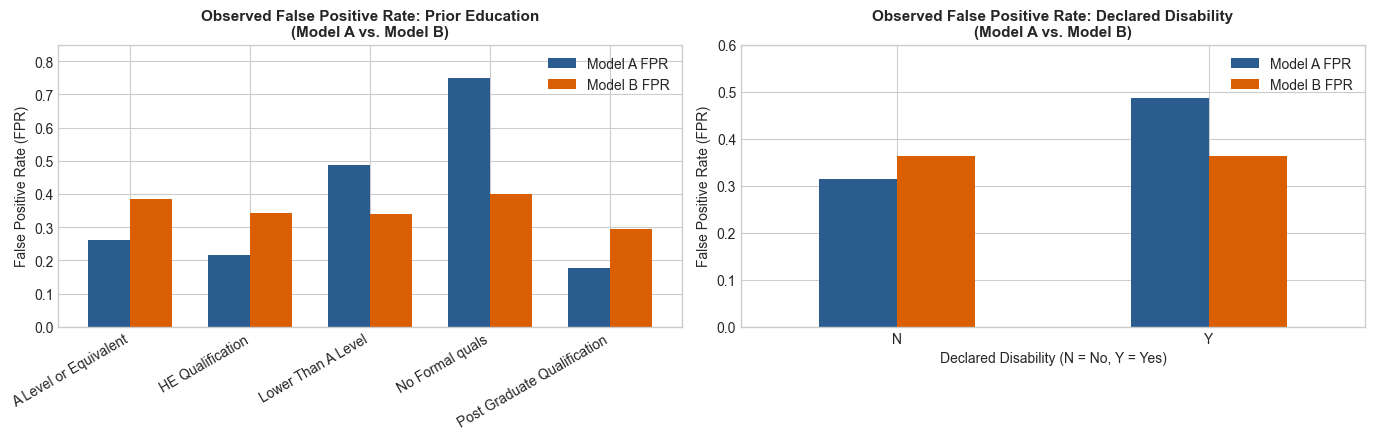

In [19]:
# Visualizing Subgroup Differences in False Positive Rate across Models
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: False Positive Rate by Prior Education
edu_fpr_plot = edu_comp.set_index('Subgroup')[['Model A FPR', 'Model B FPR']]
edu_fpr_plot.plot(kind='bar', ax=axes[0], color=['#2b5c8f', '#d95f02'], width=0.7)
axes[0].set_title('Observed False Positive Rate: Prior Education\n(Model A vs. Model B)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('False Positive Rate (FPR)', fontsize=10)
axes[0].set_xlabel('')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].set_ylim(0, 0.85)

# Plot 2: False Positive Rate by Declared Disability
dis_fpr_plot = dis_comp.set_index('Subgroup')[['Model A FPR', 'Model B FPR']]
dis_fpr_plot.plot(kind='bar', ax=axes[1], color=['#2b5c8f', '#d95f02'], width=0.5)
axes[1].set_title('Observed False Positive Rate: Declared Disability\n(Model A vs. Model B)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('False Positive Rate (FPR)', fontsize=10)
axes[1].set_xlabel('Declared Disability (N = No, Y = Yes)', fontsize=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].set_ylim(0, 0.60)

plt.tight_layout()
plt.show()

---
### 11. Final Findings and Recommendation

#### Summary of Comparative Findings:
1. **Predictive Performance Difference is Minimal:**
   * **Recall:** Model B achieves **72.60%** test recall vs. **73.41%** for Model A (a difference of **-0.81 percentage points**, or 19 fewer at-risk enrollments detected out of 2,369 in the test set).
   * **Precision:** Model B achieves **60.56%** precision vs. **63.14%** for Model A (-2.58 percentage points, corresponding to 105 additional false positives across 5,462 test enrollments).
   * **F1-Score:** 0.6604 vs. 0.6789 (-0.0185).
   * **ROC-AUC:** 0.7534 vs. 0.7745 (-0.0211).
   * **Empirical Takeaway:** Over 97% of the model's discriminative ability comes from LMS platform interaction (active days, clicks), course workload, and early assignment performance, rather than static demographic background attributes.

2. **Observed False Positive Rate Differences Across Subgroups:**
   * **Declared Disability:** In Model A, students with a declared disability had an observed test FPR of **48.72%** ($FP=114, N_{neg}=234$). In Model B, the observed test FPR decreased to **36.32%** ($FP=85, N_{neg}=234$), which is closely aligned with the FPR of students without declared disabilities (**36.20%**).
   * **Prior Education:** For students entering with *Lower Than A Level* qualifications ($N=2,093, N_{neg}=997$), the observed test FPR in Model A was **48.75%** ($FP=486$). In Model B, this dropped to **34.10%** ($FP=340$), an observed reduction of 14.65 percentage points.
   * **Cautious Assessment:** These observed reductions occur because Model A assigned positive coefficients to demographic indicators (such as declared disability and lower education), which increased baseline predicted risk regardless of student activity. Removing these indicators means Model B bases predictions entirely on observed early engagement and academic metrics. However, this does not guarantee or prove absolute fairness, as engagement itself can be influenced by external disparities.

3. **Data Collection & Privacy Considerations:**
   * Model B does not require collecting or processing the 6 demographic and socioeconomic features (`gender`, `region`, `highest_education`, `imd_band`, `age_band`, `disability`).
   * This simplifies data intake, eliminates the need for teachers to manually input sensitive personal attributes, and aligns with data minimization principles (collecting only data necessary for the task).

#### Recommendation & System Status:
* **Current Deployment:** Retain **Model A (18 features)** as the active production model in the Streamlit application to preserve established documentation and tested artifacts.
* **Future Evolution:** **Model B (12 features) is a technically viable and practical alternative**. It achieves practically equivalent risk detection (within 1% recall) while avoiding the collection of sensitive demographic data and demonstrating substantially lower false positive disparity on this dataset.

In [20]:
# Print final experimental conclusion summary
print("=== Feature Comparison Experiment Summary ===")
print("1. Performance Trade-off (Test Set, Threshold 0.40):")
print("   - Model A (18 features): Recall = 73.41%, Precision = 63.14%, F1 = 0.6789, ROC-AUC = 0.7745")
print("   - Model B (12 features): Recall = 72.60%, Precision = 60.56%, F1 = 0.6604, ROC-AUC = 0.7534")
print("   - Difference: Recall -0.81 percentage points (-19 caught), Precision -2.58 percentage points (+105 false alarms).")
print("2. Operational Threshold Context:")
print("   - Threshold 0.35 has peak OOF F1 (0.6694), but flags 61.7% of students.")
print("   - Threshold 0.40 flags 51.8% of students, maintains >= 70% recall (72.23% OOF), and matches production baseline.")
print("3. Subgroup Observations (Test Set):")
print("   - Declared Disability FPR: 48.72% (Model A) -> 36.32% (Model B), with N_neg = 234.")
print("   - Lower Than A Level FPR:  48.75% (Model A) -> 34.10% (Model B), with N_neg = 997.")
print("   - Caution: Small groups (No Formal Quals N=50, 55<= N=38) have high statistical variance.")
print("4. Conclusion:")
print("   - Model B is technically viable and achieves strong risk detection without demographic inputs.")
print("   - Model A remains the active production baseline for current deployment.")

=== Feature Comparison Experiment Summary ===
1. Performance Trade-off (Test Set, Threshold 0.40):
   - Model A (18 features): Recall = 73.41%, Precision = 63.14%, F1 = 0.6789, ROC-AUC = 0.7745
   - Model B (12 features): Recall = 72.60%, Precision = 60.56%, F1 = 0.6604, ROC-AUC = 0.7534
   - Difference: Recall -0.81 percentage points (-19 caught), Precision -2.58 percentage points (+105 false alarms).
2. Operational Threshold Context:
   - Threshold 0.35 has peak OOF F1 (0.6694), but flags 61.7% of students.
   - Threshold 0.40 flags 51.8% of students, maintains >= 70% recall (72.23% OOF), and matches production baseline.
3. Subgroup Observations (Test Set):
   - Declared Disability FPR: 48.72% (Model A) -> 36.32% (Model B), with N_neg = 234.
   - Lower Than A Level FPR:  48.75% (Model A) -> 34.10% (Model B), with N_neg = 997.
   - Caution: Small groups (No Formal Quals N=50, 55<= N=38) have high statistical variance.
4. Conclusion:
   - Model B is technically viable and achieves stro